# num-quant-peptides-plot-SMTG
3.27.25

In [49]:
import pandas as pd
import numpy as np
from scipy import stats

#from scipy.stats import false_discovery_control

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
#sns.set(context="paper", style="ticks") 
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [50]:
nettle_skyline_report_path="../results/SMTG-nettle-norm-report.csv"
gt_report_path="../results/SMTG-unimputed-norm-report.csv"

#### Read in the SMTG metadata file
The TZR samples are from SMTG. The HADT samples are brain QC.

In [51]:
smtg_metadata = pd.read_csv("../data/smtg-metadata.csv")
#smtg_metadata.head(3)

#### Read in and pre-process the Nettle imputed Skyline quants report
We want to drop the QC samples (HADTXX) as well.

In [52]:
todrop = ["Peptide", "Peptide Modified Sequence", "Protein", "Protein Name", 
          "chrlib-4mz-ovlp-400to500-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-500to600-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-600to700-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-700to800-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-800to900-Lib-B1 Normalized Area", 
          "chrlib-4mz-ovlp-900to1000-Lib-B1 Normalized Area", 
          "B1-ind-8mz-ovlp-400to1000-HADT01 Normalized Area", 
          "B2-ind-8mz-ovlp-400to1000-HADT02 Normalized Area", 
          "B3-ind-8mz-ovlp-400to1000-HADT03 Normalized Area", 
          "B4-5-ind-8mz-ovlp-400to1000-HADT04 Normalized Area", 
          "B4-5-ind-8mz-ovlp-400to1000-HADTP05 Normalized Area"]

nettle_mat = pd.read_csv(nettle_skyline_report_path)
nettle_mat = nettle_mat[nettle_mat["Protein"] != "Decoys"]

nettle_mat.index = nettle_mat["Peptide Modified Sequence"]
nettle_mat = nettle_mat.drop(columns=todrop)

# Get rid of the "normalized quant" part of the column ID
new_col_ids = [x.split(" ")[0] for x in nettle_mat.columns]
nettle_mat.columns = new_col_ids

#### Read in the unimputed ground truth Skyline report

In [53]:
gt_mat = pd.read_csv(gt_report_path)
gt_mat = gt_mat[gt_mat["Protein"] != "Decoys"]

gt_mat.index=gt_mat["Peptide Modified Sequence"]
gt_mat = gt_mat.drop(columns=todrop)

# Get rid of the "normalized quant" part of the column ID
new_col_ids = [x.split(" ")[0] for x in gt_mat.columns]
gt_mat.columns = new_col_ids

# Isolate just the sample ID from the column name
new_colnames1 = [x.split("-")[-1] for x in gt_mat.columns]
gt_mat.columns = new_colnames1

#gt_mat.head(3)
print(nettle_mat.shape)
print(gt_mat.shape)

(107555, 67)
(107555, 67)


#### Isolate just the sample ID from the column names
For both matrices. 

In [54]:
# Isolate just the sample ID from the column name
new_colnames = [x.split("-")[-1] for x in nettle_mat.columns]
nettle_mat.columns = new_colnames

# Isolate just the sample ID from the column name
new_colnames1 = [x.split("-")[-1] for x in gt_mat.columns]
gt_mat.columns = new_colnames1

#### Log the quants? 
Or maybe don't yet. 

In [55]:
# Should these be set to zero or one? 
nettle_mat[nettle_mat == 0] = np.nan
gt_mat[gt_mat == 0] = np.nan

nettle_mat = np.log(nettle_mat)
gt_mat = np.log(gt_mat)

#### Get the sample IDs corresponding to each condition 

In [56]:
meta_add = smtg_metadata[smtg_metadata["Condition"] == "Autosomal Dominant ADD"]
add_sample_ids = list(meta_add["Sample Label"])

meta_sporadic = smtg_metadata[smtg_metadata["Condition"] == "Sporadic ADD"]
sporadic_sample_ids = list(meta_sporadic["Sample Label"])

meta_hcf_low = smtg_metadata[smtg_metadata["Condition"] == "HCF/Low ADNC"]
hcf_low_sample_ids = list(meta_hcf_low["Sample Label"])

meta_hcf_high = smtg_metadata[smtg_metadata["Condition"] == "HCF/High ADNC"]
hcf_high_sample_ids = list(meta_hcf_high["Sample Label"])

print(f"Autosomal Dominant ADD: {len(add_sample_ids)}")
print(f"Sporadic ADD: {len(sporadic_sample_ids)}")
print(f"HCF/Low ADNC: {len(hcf_low_sample_ids)}")
print(f"HCF/High ADNC: {len(hcf_high_sample_ids)}")

Autosomal Dominant ADD: 24
Sporadic ADD: 18
HCF/Low ADNC: 9
HCF/High ADNC: 11


#### Isolate quants matrices for each of the four conditions 

In [57]:
# FOR THE NETTLE QUANTS MATRIX
add_nettle_mat = nettle_mat[add_sample_ids]
sporadic_nettle_mat = nettle_mat[sporadic_sample_ids]
hcf_low_nettle_mat = nettle_mat[hcf_low_sample_ids]
hcf_high_nettle_mat = nettle_mat[hcf_high_sample_ids]

add_nettle = np.array(add_nettle_mat)
sporadic_nettle = np.array(sporadic_nettle_mat)
hcf_low_nettle = np.array(hcf_low_nettle_mat)
hcf_high_nettle = np.array(hcf_high_nettle_mat)

# FOR THE GROUND TRUTH QUANTS MATRIX 
add_gt_mat = gt_mat[add_sample_ids]
sporadic_gt_mat = gt_mat[sporadic_sample_ids]
hcf_low_gt_mat = gt_mat[hcf_low_sample_ids]
hcf_high_gt_mat = gt_mat[hcf_high_sample_ids]

add_gt = np.array(add_gt_mat)
sporadic_gt = np.array(sporadic_gt_mat)
hcf_low_gt = np.array(hcf_low_gt_mat)
hcf_high_gt = np.array(hcf_high_gt_mat)

#### Count up the non-missing values for each group of samples

In [58]:
add_gt_pres = np.count_nonzero(~np.isnan(add_gt_mat), axis=0)
sporadic_gt_pres = np.count_nonzero(~np.isnan(sporadic_gt_mat), axis=0)
hcf_low_gt_pres = np.count_nonzero(~np.isnan(hcf_low_gt_mat), axis=0)
hcf_high_gt_pres = np.count_nonzero(~np.isnan(hcf_high_gt_mat), axis=0)

add_nettle_pres = np.count_nonzero(~np.isnan(add_nettle_mat), axis=0)
sporadic_nettle_pres = np.count_nonzero(~np.isnan(sporadic_nettle_mat), axis=0)
hcf_low_nettle_pres = np.count_nonzero(~np.isnan(hcf_low_nettle_mat), axis=0)
hcf_high_nettle_pres = np.count_nonzero(~np.isnan(hcf_high_nettle_mat), axis=0)

#### Might be better just to take the arithmatic means here
And represent as bar plots

In [59]:
# todo: implement this

#### Add extra characters onto the ends of the unimputed arrays
blehhh. 

In [60]:
n_toadd_sporadic = len(add_gt_pres) - len(sporadic_gt_pres)
n_toadd_hcf_low = len(add_gt_pres) - len(hcf_low_gt_pres)
n_toadd_hcf_high = len(add_gt_pres) - len(hcf_high_gt_pres)

toadd_sporadic = np.zeros(n_toadd_sporadic)
toadd_sporadic[:] = np.nan

toadd_hcf_low = np.zeros(n_toadd_hcf_low)
toadd_hcf_low[:] = np.nan

toadd_hcf_high = np.zeros(n_toadd_hcf_high)
toadd_hcf_high[:] = np.nan

sporadic_gt_pres = np.concatenate([sporadic_gt_pres, toadd_sporadic])
hcf_low_gt_pres = np.concatenate([hcf_low_gt_pres, toadd_hcf_low])
hcf_high_gt_pres = np.concatenate([hcf_high_gt_pres, toadd_hcf_high])

#### Do the same thing for the Nettle imputed arrays
There has to be an easier way of doing this. 

In [61]:
n_toadd_sporadic = len(add_nettle_pres) - len(sporadic_nettle_pres)
n_toadd_hcf_low = len(add_nettle_pres) - len(hcf_low_nettle_pres)
n_toadd_hcf_high = len(add_nettle_pres) - len(hcf_high_nettle_pres)

toadd_sporadic = np.zeros(n_toadd_sporadic)
toadd_sporadic[:] = np.nan

toadd_hcf_low = np.zeros(n_toadd_hcf_low)
toadd_hcf_low[:] = np.nan

toadd_hcf_high = np.zeros(n_toadd_hcf_high)
toadd_hcf_high[:] = np.nan

sporadic_nettle_pres = np.concatenate([sporadic_nettle_pres, toadd_sporadic])
hcf_low_nettle_pres = np.concatenate([hcf_low_nettle_pres, toadd_hcf_low])
hcf_high_nettle_pres = np.concatenate([hcf_high_nettle_pres, toadd_hcf_high])

#### Unimputed -- set up a plotting dataframe

In [62]:
cols = ["ADAD", "Sporadic", "HCF-low", "HCF-high"]
plotter_unimputed = pd.DataFrame(columns=cols)
plotter_unimputed["ADAD"] = add_gt_pres
plotter_unimputed["Sporadic"] = sporadic_gt_pres
plotter_unimputed["HCF-low"] = hcf_low_gt_pres
plotter_unimputed["HCF-high"] = hcf_high_gt_pres

#### Nettle -- set up plotting dataframe 

In [63]:
cols = ["ADAD", "Sporadic", "HCF-low", "HCF-high"]
plotter_nettle = pd.DataFrame(columns=cols)
plotter_nettle["ADAD"] = add_nettle_pres
plotter_nettle["Sporadic"] = sporadic_nettle_pres
plotter_nettle["HCF-low"] = hcf_low_nettle_pres
plotter_nettle["HCF-high"] = hcf_high_nettle_pres

#### Combine into a single dataframe
Hopefully to enable plotting. 

In [64]:
plotter_melt_unimputed = plotter_unimputed.melt()
plotter_melt_nettle = plotter_nettle.melt()

plotter_melt_unimputed.columns = ["group", "peptides"]
plotter_melt_nettle.columns = ["group", "peptides"]

plotter_melt_unimputed["condition"] = "Unimputed"
plotter_melt_nettle["condition"] = "Nettle"

merged = pd.concat([plotter_melt_unimputed, plotter_melt_nettle], ignore_index=True)

#### Set up a custom color palette? 

In [65]:
cmap_cust = list(plt.cm.tab10.colors)
cmap_cust[0] = cmap_cust[4]
cmap_cust[1] = cmap_cust[7]
cmap_cust = tuple(cmap_cust)

#### Plot that sucker 

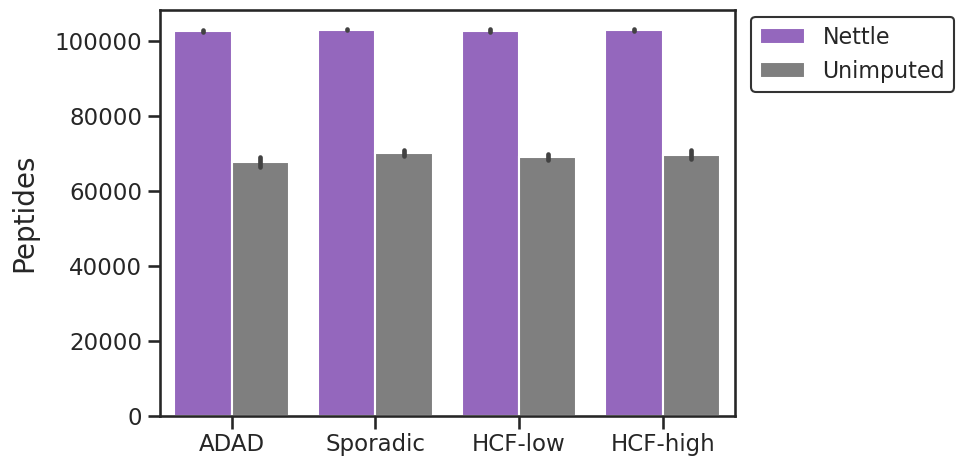

In [67]:
order = ["Nettle", "Unimputed"]

fig, ax = plt.subplots(figsize=(10,5))

sns.barplot(
    data=merged, 
    x="group", y="peptides",
    hue="condition",
    #palette="tab10", 
    palette=cmap_cust, 
    fill=True, 
    saturation=1.0,
    hue_order=order,
)

plt.xlabel("", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

plt.legend(edgecolor="black", prop={"size":16}, bbox_to_anchor=(1.01, 1.01))

plt.tight_layout()
#plt.savefig("../figures/peptide-quants-per-condition-v2.png", dpi=250, bbox_inches="tight")
#plt.savefig("../figures/peptide-quants-per-condition-SMTG.pdf", bbox_inches="tight")

#### Get the means 

In [22]:
print(np.nanmean(plotter_nettle))
print(np.nanmean(plotter_unimputed))

102840.01612903226
69062.6129032258
